In [1]:
import sys, time
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from src.config import load_config
from src.spark_session import get_spark
from src.evaluation.metrics import evaluate
from src.evaluation.stats import paired_bootstrap
from src.models.popularity import add_recent_counts, smoothed_ctr
from src.models.embeddings import user_profiles_dense, score_dense
from src.models.hybrid import zscore, weighted
from src.models.als import build_interactions, fit_indexers, add_indices, fit_als, score_als

cfg = load_config("small")
spark = get_spark(cfg)
spark.sparkContext.setCheckpointDir(str(ROOT / "data" / "checkpoints"))
OUT = cfg["paths"]["processed"]
RES = ROOT / "results" / "metrics"
FIG = cfg["paths"]["figures"]

# Configuraciones fijadas en val
W_HIBRIDO = 0.4          # puntaje z
ALS_RANK, ALS_ALPHA = 32, 10
DELTA = 0.01
T_INICIO = time.time()

resultados, por_imp = [], {}

def evaluar(df, expr, nombre):
    """Evalúa, guarda el resumen y las métricas por impresión (para bootstrap y segmentos)."""
    t0 = time.time()
    per_imp, res = evaluate(df.withColumn("score", expr))
    por_imp[nombre] = per_imp.select("impression_id", "n", "auc", "mrr", "ndcg5", "ndcg10").toPandas()
    per_imp.unpersist()
    resultados.append({"modelo": nombre, **res})
    print(f"{nombre:14s} AUC = {res['auc']:.4f} | MRR = {res['mrr']:.4f} | "
          f"nDCG@5 = {res['ndcg5']:.4f} ({time.time() - t0:.0f} s)")

In [2]:
t0 = time.time()
imp = spark.read.parquet(str(OUT / "impressions_long"))
beh = spark.read.parquet(str(OUT / "behaviors"))

p0 = imp.filter(F.col("periodo").isin("train", "val")).agg(F.avg("label")).first()[0]

# Test (15 nov) + las 24 h previas (14 nov = periodo val)
base = (imp.filter(F.col("periodo").isin("val", "test"))
           .select("impression_id", "user_id", "time", "news_id", "label", "periodo"))
cands = (add_recent_counts(base, hours=(24,))
         .filter("periodo = 'test'")
         .withColumn("ctr", smoothed_ctr(24, 20, p0))
         .select("impression_id", "user_id", "news_id", "label", "ctr"))

users_test = (beh.filter("periodo = 'test'")
                 .select("user_id", "history", "hist_len")
                 .dropDuplicates(["user_id"]).cache())

print(f"p0 (9–14 nov) = {p0:.4f} ({time.time() - t0:.0f} s)")

p0 (9–14 nov) = 0.0404 (10 s)


In [3]:
t0 = time.time()
news_emb = spark.read.parquet(str(OUT / "news_emb_minilm")).cache()
profiles = user_profiles_dense(users_test, news_emb, k=None)

senales = (score_dense(cands, news_emb, profiles)
           .withColumn("emb_resp", F.coalesce("cos", "ctr"))        # embeddings, CTR si no hay historial
           .withColumn("ctr_z", zscore("ctr"))
           .withColumn("cos_z", zscore("cos"))
           .withColumn("hibrido", weighted("cos_z", "ctr_z", W_HIBRIDO))
           .select("impression_id", "user_id", "news_id", "label", "ctr", "emb_resp", "hibrido")
           .cache())

print(f"Candidatas de test: {senales.count():,} ({time.time() - t0:.0f} s)")

Candidatas de test: 2,740,998 (692 s)


In [4]:
t0 = time.time()
inter = build_interactions(beh, imp, hist_periods=("train", "val", "test"),
                           click_periods=("train", "val")).cache()
u_idx, i_idx = fit_indexers(inter)
n_i = len(i_idx.labelsArray[0])
inter_idx = add_indices(inter, u_idx, i_idx).select("u", "i", "r").cache()
model = fit_als(inter_idx, rank=ALS_RANK, alpha=ALS_ALPHA)

cands_idx = add_indices(cands.select("impression_id", "user_id", "news_id", "label"), u_idx, i_idx)
als_scored = (score_als(model, cands_idx, cold="neutral")
              .withColumn("item_frio", F.col("i") == n_i)
              .select("impression_id", "label", "score_als", "item_frio")
              .cache())

als_scored.agg(F.round(F.avg(F.col("item_frio").cast("int")), 3).alias("pct_candidatas_frias"),
               F.round(F.sum(F.col("label") * F.col("item_frio").cast("int")) / F.sum("label"), 3)
                .alias("pct_clics_frios")).show()
print(f"Celda 4: {time.time() - t0:.0f} s")

+--------------------+---------------+
|pct_candidatas_frias|pct_clics_frios|
+--------------------+---------------+
|               0.523|          0.488|
+--------------------+---------------+

Celda 4: 63 s


In [5]:
evaluar(senales, F.rand(1), "aleatorio")
evaluar(senales, F.col("ctr"), "baseline_ctr")
evaluar(senales, F.col("emb_resp"), "embeddings")
evaluar(als_scored, F.col("score_als"), "als")
evaluar(senales, F.col("hibrido"), "hibrido")

tabla = (pd.DataFrame(resultados)[["modelo", "auc", "mrr", "ndcg5", "ndcg10", "impresiones"]]
         .sort_values("auc", ascending=False).reset_index(drop=True))
print(f"\nTiempo acumulado: {(time.time() - T_INICIO) / 60:.1f} min")
tabla.round(4)

aleatorio      AUC = 0.5007 | MRR = 0.2188 | nDCG@5 = 0.2238 (10 s)
baseline_ctr   AUC = 0.6526 | MRR = 0.3115 | nDCG@5 = 0.3403 (7 s)
embeddings     AUC = 0.6407 | MRR = 0.3084 | nDCG@5 = 0.3370 (6 s)
als            AUC = 0.5305 | MRR = 0.2427 | nDCG@5 = 0.2531 (14 s)
hibrido        AUC = 0.6832 | MRR = 0.3349 | nDCG@5 = 0.3712 (7 s)

Tiempo acumulado: 13.5 min


,modelo,auc,mrr,ndcg5,ndcg10,impresiones
0,hibrido,0.6832,0.3349,0.3712,0.4333,73152
1,baseline_ctr,0.6526,0.3115,0.3403,0.4025,73152
2,embeddings,0.6407,0.3084,0.3370,0.3966,73152
3,als,0.5305,0.2427,0.2531,0.3121,73152
4,aleatorio,0.5007,0.2188,0.2238,0.2866,73152


In [6]:
m = por_imp["hibrido"].merge(por_imp["baseline_ctr"], on="impression_id", suffixes=("_h", "_b"))

filas_bs = []
for met in ("auc", "mrr", "ndcg5", "ndcg10"):
    dif, ic, medias = paired_bootstrap(m[f"{met}_h"], m[f"{met}_b"])
    filas_bs.append({"metrica": met, "diferencia": dif, "ic_inf": ic[0], "ic_sup": ic[1],
                     "p_dif_menor_igual_0": np.mean(medias <= 0),
                     "p_dif_menor_igual_delta": np.mean(medias <= DELTA)})
bootstrap = pd.DataFrame(filas_bs)

auc_bs = bootstrap.iloc[0]
print(f"H1 (AUC híbrido − AUC baseline ≥ {DELTA}): "
      f"{'SE ACEPTA' if auc_bs['ic_inf'] > DELTA else 'NO SE ACEPTA'} "
      f"(IC 95 % = [{auc_bs['ic_inf']:+.4f}, {auc_bs['ic_sup']:+.4f}])")
bootstrap.round(4)

H1 (AUC híbrido − AUC baseline ≥ 0.01): SE ACEPTA (IC 95 % = [+0.0294, +0.0318])


,metrica,diferencia,ic_inf,ic_sup,p_dif_menor_igual_0,p_dif_menor_igual_delta
0,auc,0.0305,0.0294,0.0318,0.0,0.0
1,mrr,0.0234,0.0223,0.0246,0.0,0.0
2,ndcg5,0.0309,0.0296,0.0322,0.0,0.0
3,ndcg10,0.0308,0.0297,0.0320,0.0,0.0


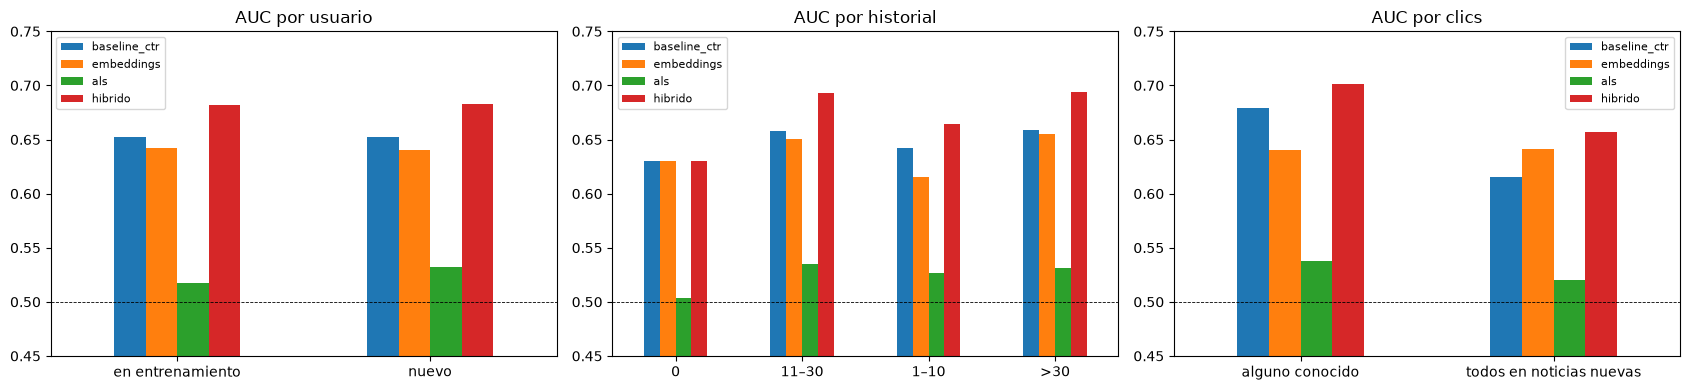


== usuario ==
modelo            baseline_ctr  embeddings     als  hibrido  impresiones
usuario                                                                 
en entrenamiento        0.6520      0.6418  0.5172   0.6824         8959
nuevo                   0.6527      0.6406  0.5323   0.6833        64193

== historial ==
modelo     baseline_ctr  embeddings     als  hibrido  impresiones
historial                                                        
0                0.6306      0.6306  0.5040   0.6306         2214
11–30            0.6575      0.6501  0.5351   0.6934        23754
1–10             0.6424      0.6154  0.5270   0.6644        21907
>30              0.6588      0.6548  0.5314   0.6944        25277

== clics ==
modelo                    baseline_ctr  embeddings     als  hibrido  impresiones
clics                                                                           
alguno conocido                 0.6787      0.6406  0.5377   0.7017        42902
todos en noticias nuevas

In [7]:
# Usuarios presentes en entrenamiento (como Overlap/Unseen Users del paper de MIND)
usr_train = (beh.filter(F.col("periodo").isin("train", "val"))
                .select("user_id").distinct().withColumn("en_train", F.lit(True)))

# Impresiones donde todos los clics caen en noticias desconocidas para ALS
clic_frio = (als_scored.filter("label = 1").groupBy("impression_id")
                       .agg(F.min(F.col("item_frio").cast("int")).alias("todos_clics_frios")))

seg = (beh.filter("periodo = 'test'")
          .select("impression_id", "user_id", "hist_len", "imp_len")
          .join(F.broadcast(usr_train), "user_id", "left")
          .join(clic_frio, "impression_id", "left")
          .toPandas())
seg["usuario"] = np.where(seg["en_train"].fillna(False).astype(bool), "en entrenamiento", "nuevo")
seg["historial"] = pd.cut(seg["hist_len"], [-1, 0, 10, 30, 10**6],
                          labels=["0", "1–10", "11–30", ">30"]).astype(str)
seg["clics"] = np.where(seg["todos_clics_frios"] == 1, "todos en noticias nuevas", "alguno conocido")

modelos = ["baseline_ctr", "embeddings", "als", "hibrido"]
largo = (pd.concat([por_imp[mo][["impression_id", "auc"]].assign(modelo=mo) for mo in modelos])
           .merge(seg, on="impression_id"))

tablas_seg = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, dim in zip(axes, ["usuario", "historial", "clics"]):
    t = largo.pivot_table(index=dim, columns="modelo", values="auc", aggfunc="mean")[modelos]
    t["impresiones"] = seg.groupby(dim).size()
    tablas_seg[dim] = t
    t[modelos].plot.bar(ax=ax, rot=0)
    ax.set_ylim(0.45, 0.75); ax.axhline(0.5, color="k", lw=0.6, ls="--")
    ax.set_title(f"AUC por {dim}"); ax.set_xlabel(""); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "07_auc_por_segmento.png", dpi=150); plt.show()

for dim, t in tablas_seg.items():
    print(f"\n== {dim} ==")
    print(t.round(4).to_string())

In [8]:
INCLUDE_TFIDF = False      # cambia a True si tienes 15–25 minutos más

if INCLUDE_TFIDF:
    from src.models.content import fit_tfidf, user_profiles, score_content
    t0 = time.time()
    news = spark.read.parquet(str(OUT / "news"))
    model_t, vectorizer = fit_tfidf(news, min_df=5)
    news_vec = model_t.transform(news).select("news_id", "tokens", "vec").cache()
    prof_t = user_profiles(users_test, news_vec, vectorizer, k=None)
    tf = score_content(cands, news_vec, prof_t).withColumn("tfidf_resp", F.coalesce("cos", "ctr"))
    evaluar(tf, F.col("tfidf_resp"), "tfidf")
    tabla = (pd.DataFrame(resultados)[["modelo", "auc", "mrr", "ndcg5", "ndcg10", "impresiones"]]
             .sort_values("auc", ascending=False).reset_index(drop=True))
    print(f"TF-IDF: {time.time() - t0:.0f} s")

In [9]:
tabla.assign(periodo="test", dataset=cfg["dataset"]).to_csv(RES / "07_test_final.csv", index=False)
bootstrap.to_csv(RES / "07_bootstrap_hibrido_vs_baseline.csv", index=False)
for dim, t in tablas_seg.items():
    t.to_csv(RES / f"07_segmentos_{dim}.csv")
pd.concat([d.assign(modelo=k) for k, d in por_imp.items()]) \
  .to_parquet(RES / "07_metricas_por_impresion.parquet", index=False)

print(f"Tiempo total: {(time.time() - T_INICIO) / 60:.1f} min")
spark.stop()

Tiempo total: 13.8 min
